# 5. Join your data by edge_id

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/05_join_by_edge_id.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/05_join_by_edge_id.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You join traffic counts to the edges by `edge_id` and color the map by the counts. The counts in this notebook are made up.

`edge_id` is a `BIGINT` content hash of the OSM way and the two ends of the edge. It is the same after a rebuild, so data joined on it stays correct.

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
net                                                   # the card

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## Make the counts

One count for each direction of the main roads, as an external file can give them. Keep the column type `int64`: a float or a text column loses the hash.

In [3]:
import numpy as np

main = net.edges(where="highway IN ('primary', 'secondary', 'tertiary')")      # the main roads
base = main.highway.map({"primary": 900, "secondary": 500, "tertiary": 250})   # vehicles per hour, by road class
rng = np.random.default_rng(1)                                                 # made-up numbers that do not change
counts = main[["edge_id"]].assign(vehicles_per_hour=(base * rng.uniform(0.5, 1.5, len(main))).round().astype(int))
counts.head()                                                                  # edge_id (int64) and the count

,edge_id,vehicles_per_hour
0,24138324208710596,506
1,25722618171067748,1305
2,27407470953641313,322
3,30114210838040685,724
4,54233354089271892,406


## Join on edge_id

In [4]:
gdf = net.edges().merge(counts, on="edge_id", how="left")                    # the edges with their counts
gdf.nlargest(5, "vehicles_per_hour")[["edge_id", "name", "highway", "vehicles_per_hour"]]    # the five largest counts

,edge_id,name,highway,vehicles_per_hour
2246,7273866584570309072,NaN,primary,1324.0
650,2112309560693974313,Boulevard du Larvotto,primary,1312.0
652,2113142360788194299,NaN,primary,1309.0
2610,8528436742631886103,Tunnel Pasteur,primary,1308.0
607,1943370964926618174,Tunnel Albert II,primary,1307.0


## Color the map by the counts

`color_by` takes your own data keyed by `edge_id`. Edges without a count are gray. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

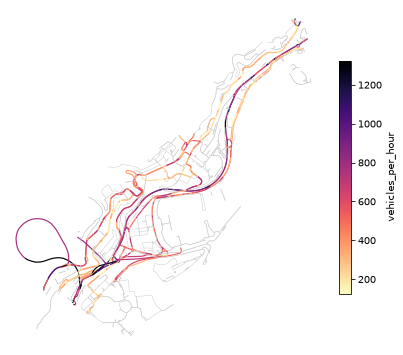

In [5]:
by_edge = counts.set_index("edge_id").vehicles_per_hour    # the counts as a Series keyed by edge_id
net.map(color_by=by_edge, cmap="magma_r")                  # a map, colored by the count

In [6]:
net.save_map("out/counts.html", color_by=by_edge, cmap="magma_r")    # the same map as one HTML file

PosixPath('out/counts.html')

## A dashboard

roadstyle's dashboard: the map, the card of the road that you click and the color menu. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

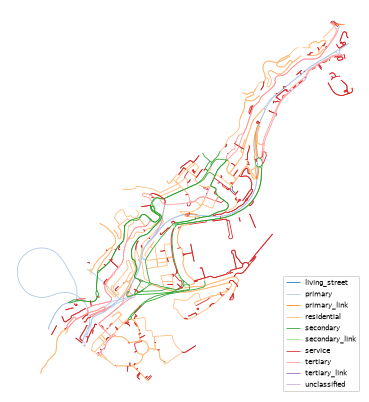

In [7]:
net.dashboard()    # the dashboard page of the network

## The ids stay after a rebuild

Build Monaco again into a new file. The same counts join to the same edges, with no change.

In [8]:
again = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco_again")    # the same area, built again into a new file
counts.edge_id.isin(again.edges().edge_id).all()                              # each count still finds its edge

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco_again.duckdb

np.True_